# 4. Hafta - Özellik Mühendisliği (İP-3)
Bu not defteri; 3. haftada temizlenen veri üzerine **train/test ayırma (FR-06)**, **kategorik dönüşüm (FR-05)**,
**ölçekleme** ve **hedef değişkene log dönüşümü** adımlarını içerir.

Tüm öğrenilen adımlar (medyan/mod dolgusu, encoding, scaling) tek bir `ColumnTransformer` içinde toplanmış ve
**yalnızca eğitim kümesi üzerinde `fit` edilmiştir**. Böylece veri sızıntısı önlenir (NFR-01).
Sabit `RANDOM_STATE` ile deneyler tekrarlanabilir (NFR-02).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # NFR-02: Tekrarlanabilirlik

df = pd.read_csv("train.csv")
print(f"Başlangıç boyutu: {df.shape}")

Başlangıç boyutu: (1460, 81)


## 1. Değişken özeti (FR-02)
3. haftada eksik kalan değişken tipi ve özet istatistik tablosu.

In [2]:
ozet = pd.DataFrame({
    "tip": df.dtypes.astype(str),
    "eksik_sayisi": df.isnull().sum(),
    "eksik_yuzde": (df.isnull().mean() * 100).round(1),
    "benzersiz_deger": df.nunique(),
})
print(f"Sayısal değişken: {df.select_dtypes(include=np.number).shape[1]}, "
      f"Kategorik değişken: {df.select_dtypes(exclude=np.number).shape[1]}")
ozet.sort_values("eksik_sayisi", ascending=False).head(20)

Sayısal değişken: 38, Kategorik değişken: 43


,tip,eksik_sayisi,eksik_yuzde,benzersiz_deger
PoolQC,str,1453,99.5,3
MiscFeature,str,1406,96.3,4
Alley,str,1369,93.8,2
Fence,str,1179,80.8,4
MasVnrType,str,872,59.7,3
FireplaceQu,str,690,47.3,5
LotFrontage,float64,259,17.7,110
GarageQual,str,81,5.5,5
GarageFinish,str,81,5.5,3
GarageType,str,81,5.5,6


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


## 2. Veriden öğrenilmeyen (deterministik) temizlik
Aşağıdaki işlemler veri istatistiği kullanmadığı için ayırmadan önce yapılabilir; sızıntıya yol açmaz.
- 4.000 sq ft üzeri aykırı değerlerin çıkarılması (De Cock, 2011)
- Mantıksal yokluk dolguları (`None` / `0`)

In [4]:
# Aykırı değer temizliği (3. hafta ile aynı kural)
df = df.drop(df[df["GrLivArea"] > 4000].index).reset_index(drop=True)

# "NA" = özelliğin olmaması (havuz yok, garaj yok, bodrum yok ...)
cols_none = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
             "BsmtFinType2", "MasVnrType"]
df[cols_none] = df[cols_none].fillna("None")

cols_zero = ["GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2",
             "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
             "MasVnrArea"]
df[cols_zero] = df[cols_zero].fillna(0)

print(f"Temizlik sonrası boyut: {df.shape}")

Temizlik sonrası boyut: (1456, 81)


## 3. Yeni özellik türetme ve sütun eleme
- **TotalSF**: Bodrum + 1. kat + 2. kat alanı (toplam kullanılabilir alan)
- **HouseAge / RemodAge**: Satış anındaki bina yaşı ve yenilemeden bu yana geçen süre
- **TotalBath**: Yarım banyolar 0.5 sayılarak toplam banyo sayısı
- **MSSubClass** sayı gibi görünse de bir kategori koddur; metne çevrilir.

Elenenler:
- `Id`: Bilgi taşımaz.
- `GarageArea`: `GarageCars` ile r≈0.89 iç korelasyon (3. hafta heatmap bulgusu).
- `GarageYrBlt`: Garajsız evlerde anlamsız (0 yılı modeli bozar), `YearBuilt` ile çok yüksek korelasyonlu.
- `YrSold`, `YearBuilt`, `YearRemodAdd`: Bilgileri yaş değişkenlerine aktarıldı.

In [5]:
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
df["TotalBath"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                   + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])
df["MSSubClass"] = df["MSSubClass"].astype(str)

drop_cols = ["Id", "GarageArea", "GarageYrBlt", "YrSold",
             "YearBuilt", "YearRemodAdd"]
df = df.drop(columns=drop_cols)

print("Yeni özelliklerin SalePrice ile korelasyonu:")
print(df[["TotalSF", "HouseAge", "RemodAge", "TotalBath", "SalePrice"]]
      .corr()["SalePrice"].drop("SalePrice").round(2))

Yeni özelliklerin SalePrice ile korelasyonu:
TotalSF      0.83
HouseAge    -0.54
RemodAge    -0.52
TotalBath    0.64
Name: SalePrice, dtype: float64


## 4. Hedef değişkene log dönüşümü
3. haftada tespit edilen sağa çarpıklık `log1p` ile giderilir. Tahminler sonradan `np.expm1` ile dolara geri çevrilir.

SalePrice çarpıklık - önce: 1.57, sonra (log1p): 0.07


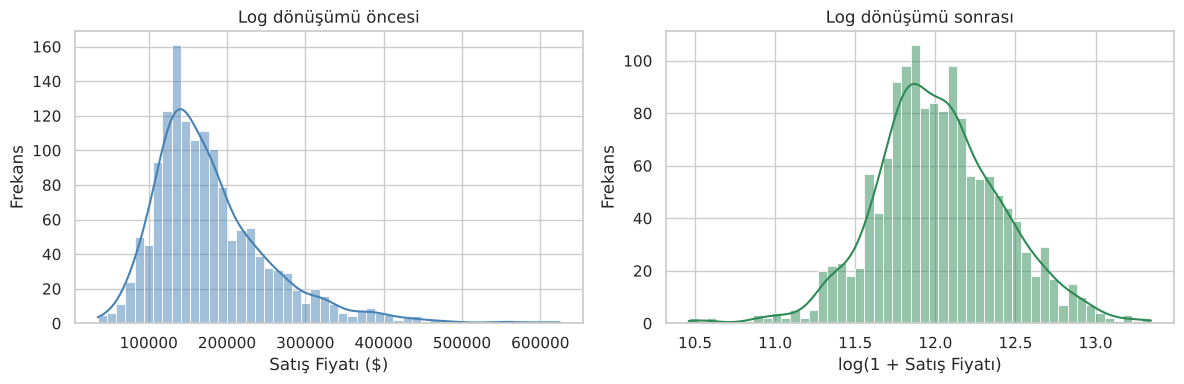

In [6]:
X = df.drop(columns="SalePrice")
y = np.log1p(df["SalePrice"])

print(f"SalePrice çarpıklık - önce: {df['SalePrice'].skew():.2f}, "
      f"sonra (log1p): {y.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Log dönüşümü öncesi")
axes[0].set_xlabel("Satış Fiyatı ($)")
axes[0].set_ylabel("Frekans")
sns.histplot(y, kde=True, bins=50, ax=axes[1], color="seagreen")
axes[1].set_title("Log dönüşümü sonrası")
axes[1].set_xlabel("log(1 + Satış Fiyatı)")
axes[1].set_ylabel("Frekans")
plt.tight_layout()
plt.savefig("log_transform.png", dpi=300)  # NFR-05: yüksek çözünürlük
plt.show()

## 5. Train / Test ayırma (FR-06)
Ayırma, öğrenilen tüm ön işleme adımlarından **önce** yapılır.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Eğitim: {X_train.shape}  ({len(X_train) / len(X):.0%})")
print(f"Test  : {X_test.shape}  ({len(X_test) / len(X):.0%})")

Eğitim: (1164, 78)  (80%)
Test  : (292, 78)  (20%)


## 6. Sütun grupları
- **Ordinal**: Doğal sırası olan kalite/derece sütunları (Po < Fa < TA < Gd < Ex)
- **Nominal**: Sırasız kategoriler → One-Hot
- **Sayısal**: Medyan dolgusu + StandardScaler
- **LotFrontage**: Eğitim kümesindeki mahalle medyanı ile doldurulur (3. hafta yöntemi, sızıntısız hali)

In [8]:
qual = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ordinal_map = {
    "ExterQual": qual, "ExterCond": qual, "BsmtQual": qual, "BsmtCond": qual,
    "HeatingQC": qual, "KitchenQual": qual, "FireplaceQu": qual,
    "GarageQual": qual, "GarageCond": qual, "PoolQC": qual,
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
}
ordinal_cols = list(ordinal_map.keys())

nominal_cols = [c for c in X_train.select_dtypes(exclude=np.number).columns
                if c not in ordinal_cols]
numeric_cols = [c for c in X_train.select_dtypes(include=np.number).columns
                if c != "LotFrontage"]

print(f"Ordinal: {len(ordinal_cols)}, Nominal: {len(nominal_cols)}, "
      f"Sayısal: {len(numeric_cols)} + LotFrontage")

Ordinal: 14, Nominal: 30, Sayısal: 33 + LotFrontage


In [9]:
class NeighborhoodMedianImputer(BaseEstimator, TransformerMixin):
    """LotFrontage eksiklerini mahalle medyanıyla doldurur.

    Medyanlar yalnızca fit() sırasında (eğitim kümesinde) öğrenilir.
    Eğitimde görülmeyen mahalleler için genel medyan kullanılır.
    """

    def fit(self, X, y=None):
        self.medians_ = X.groupby("Neighborhood")["LotFrontage"].median()
        self.global_median_ = X["LotFrontage"].median()
        return self

    def transform(self, X):
        filled = X["LotFrontage"].fillna(X["Neighborhood"].map(self.medians_))
        filled = filled.fillna(self.global_median_)
        return filled.to_frame()

    def get_feature_names_out(self, input_features=None):
        return np.array(["LotFrontage"])


ordinal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="None")),
    ("encode", OrdinalEncoder(categories=[ordinal_map[c] for c in ordinal_cols],
                              handle_unknown="use_encoded_value",
                              unknown_value=-1)),
    ("scale", StandardScaler()),
])

nominal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),  # Örn. Electrical
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

lotfrontage_pipe = Pipeline([
    ("impute", NeighborhoodMedianImputer()),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipe, ordinal_cols),
    ("nominal", nominal_pipe, nominal_cols),
    ("numeric", numeric_pipe, numeric_cols),
    ("lotfrontage", lotfrontage_pipe, ["LotFrontage", "Neighborhood"]),
])

## 7. Ön işlemeyi uygulama
`fit_transform` yalnızca eğitim kümesinde, test kümesinde sadece `transform` (NFR-01).

In [10]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print(f"Encoding öncesi sütun sayısı : {X_train.shape[1]}")
print(f"Encoding sonrası sütun sayısı: {X_train_prep.shape[1]}")
print(f"X_train_prep: {X_train_prep.shape}, X_test_prep: {X_test_prep.shape}")
print(f"Eğitimde kalan NaN: {np.isnan(X_train_prep).sum()}, "
      f"Testte kalan NaN: {np.isnan(X_test_prep).sum()}")

Encoding öncesi sütun sayısı : 78
Encoding sonrası sütun sayısı: 252
X_train_prep: (1164, 252), X_test_prep: (292, 252)
Eğitimde kalan NaN: 0, Testte kalan NaN: 0


In [11]:
# Kontrol: ölçeklenmiş sayısal sütunlar eğitimde ortalama≈0, std≈1 olmalı
X_train_df = pd.DataFrame(X_train_prep, columns=feature_names, index=X_train.index)
kontrol = ["numeric__TotalSF", "numeric__GrLivArea", "ordinal__ExterQual",
           "lotfrontage__LotFrontage"]
X_train_df[kontrol].describe().loc[["mean", "std"]].round(3)

,numeric__TotalSF,numeric__GrLivArea,ordinal__ExterQual,lotfrontage__LotFrontage
mean,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0


## 8. Sonraki hafta (İP-4) için kullanım
Modeller doğrudan bu ön işleyiciye bağlanacaktır; böylece her model aynı, sızıntısız veriyle eğitilir:

```python
from sklearn.ensemble import RandomForestRegressor
model = Pipeline([("prep", preprocessor),
                  ("reg", RandomForestRegressor(random_state=RANDOM_STATE))])
model.fit(X_train, y_train)
y_pred = np.expm1(model.predict(X_test))   # dolara geri çevirme
```